In [1]:
# Cell 1: Imports and Setup
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Set plot style
%matplotlib inline
sns.set_theme(style="whitegrid")

In [2]:
# Cell 2: Load dataset and split features/target
df = pd.read_csv("breast-cancer.csv.zip")

# Separate features (drop ID and target diagnosis)
X = df.drop(columns=["id", "diagnosis"])

# Map target: 'M' (Malignant) to 0, 'B' (Benign) to 1
y = df["diagnosis"].map({"M": 0, "B": 1})

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data loaded successfully.")
print(
    f"Training shape: {X_train_scaled.shape}, Testing shape: {X_test_scaled.shape}"
)

Data loaded successfully.
Training shape: (455, 30), Testing shape: (114, 30)


In [3]:
# Cell 3: Custom Gradient Descent Classifier Implementation
class CustomLogisticRegression:

    def __init__(self, learning_rate=0.1, iterations=2000):
        self.lr = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        y_array = y.values if isinstance(y, pd.Series) else y

        for _ in range(self.iterations):
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            # Binary Cross-Entropy Loss
            epsilon = 1e-15
            y_pred_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            loss = -(1 / n_samples) * np.sum(
                y_array * np.log(y_pred_clipped)
                + (1 - y_array) * np.log(1 - y_pred_clipped)
            )
            self.loss_history.append(loss)

            # Compute Gradients
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y_array))
            db = (1 / n_samples) * np.sum(y_predicted - y_array)

            # Update Parameters
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [4]:


# Cell 4: Train models and output benchmark comparison table

from sklearn.calibration import CalibratedClassifierCV

models = {
    "Custom Logistic Regression": CustomLogisticRegression(
        learning_rate=0.1, iterations=2000
    ),
    "Support Vector Machine": CalibratedClassifierCV(
        SVC(random_state=42), ensemble=False
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
}

results = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)

    if name == "Custom Logistic Regression":
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)
    else:
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "y_pred": y_pred,
        "y_prob": y_prob,
    }

metrics_df = pd.DataFrame(results).T[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
]

metrics_df


Training Custom Logistic Regression...
Training Support Vector Machine...
Training Random Forest...


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Custom Logistic Regression,0.964912,0.985714,0.958333,0.971831,0.996032
Support Vector Machine,0.982456,0.986111,0.986111,0.986111,0.99504
Random Forest,0.95614,0.958904,0.972222,0.965517,0.993882


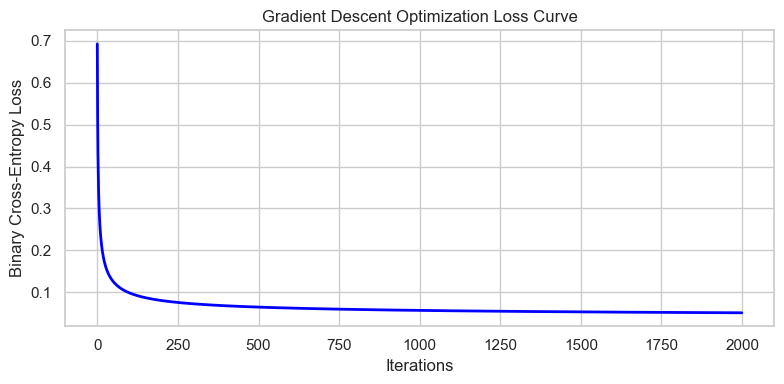

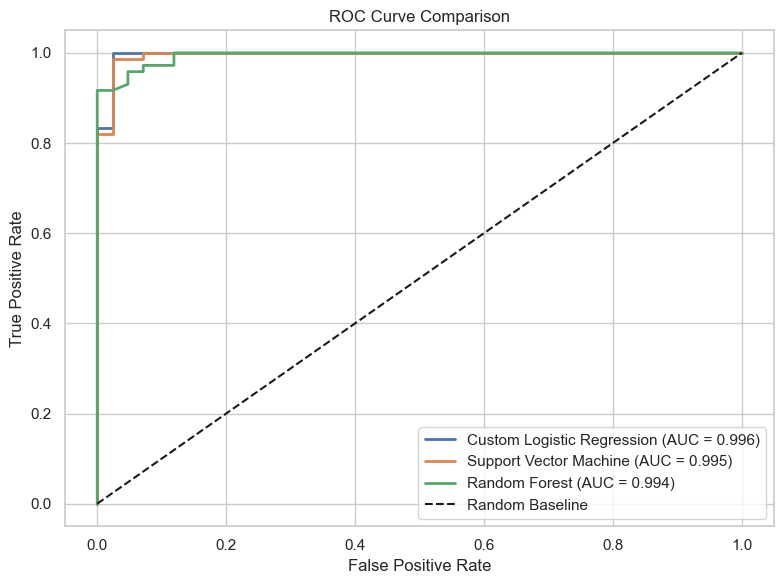

In [5]:
# Cell 5: Generate Loss Convergence Plot & ROC Curves
plt.figure(figsize=(8, 4))
plt.plot(
    models["Custom Logistic Regression"].loss_history,
    color="blue",
    linewidth=2,
)
plt.title("Gradient Descent Optimization Loss Curve")
plt.xlabel("Iterations")
plt.ylabel("Binary Cross-Entropy Loss")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, results[name]["y_prob"])
    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})",
        linewidth=2,
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()
plt.show()


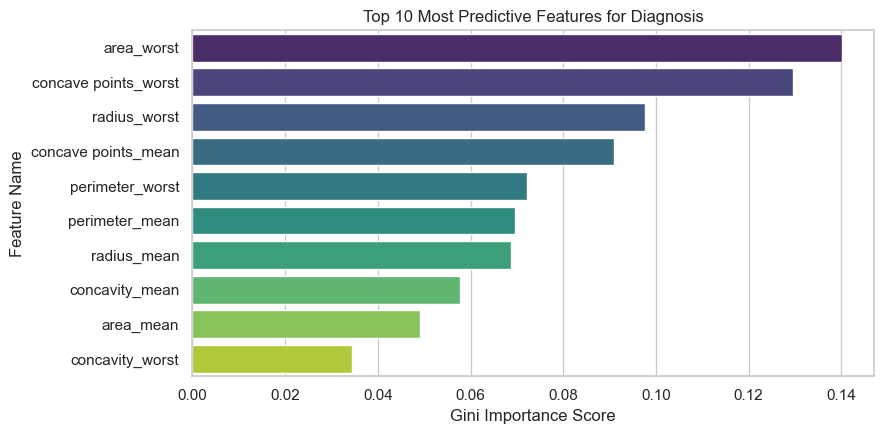

In [12]:


# Cell 6: Plot Top 10 Most Influential Features

rf_model = models["Random Forest"]

importances = pd.Series(
    rf_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 4.5))

sns.barplot(
    x=importances.head(10).values,
    y=importances.head(10).index,
    hue=importances.head(10).index,
    palette="viridis",
    legend=False,
)

plt.title("Top 10 Most Predictive Features for Diagnosis")
plt.xlabel("Gini Importance Score")
plt.ylabel("Feature Name")
plt.tight_layout()
plt.show()


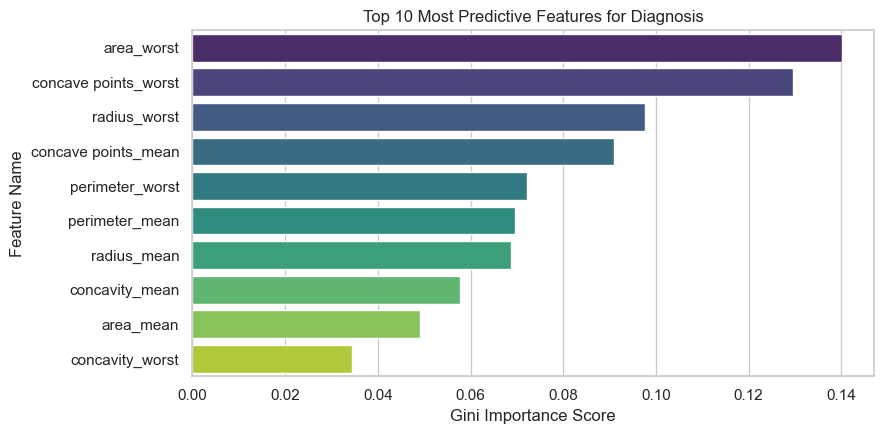

In [13]:

# Cell 7: Plot Top 10 Most Influential Features

rf_model = models["Random Forest"]

importances = pd.Series(
    rf_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 4.5))

sns.barplot(
    x=importances.head(10).values,
    y=importances.head(10).index,
    hue=importances.head(10).index,
    palette="viridis",
    legend=False,
)

plt.title("Top 10 Most Predictive Features for Diagnosis")
plt.xlabel("Gini Importance Score")
plt.ylabel("Feature Name")
plt.tight_layout()
plt.show()


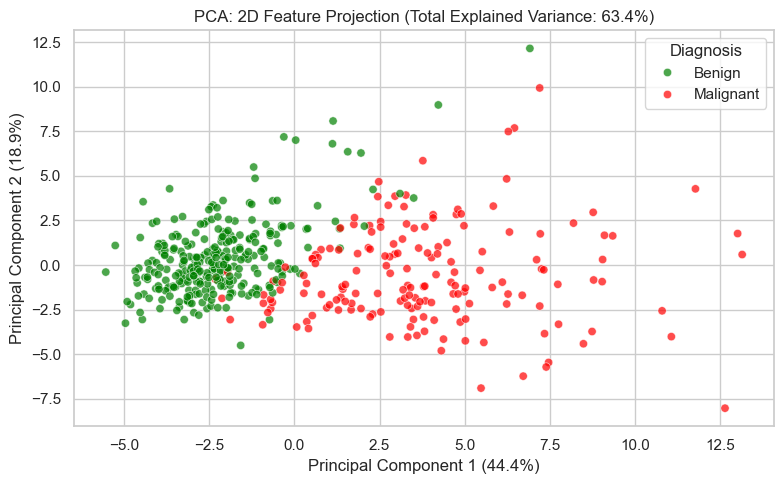

In [8]:
# Cell 8: PCA 2D Cluster Visualization
from sklearn.decomposition import PCA

# Fit PCA on scaled features
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

pca_df = pd.DataFrame(data=X_pca, columns=["PC1", "PC2"])
pca_df["Diagnosis"] = y_train.map({0: "Malignant", 1: "Benign"}).values

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x="PC1",
    y="PC2",
    hue="Diagnosis",
    data=pca_df,
    palette={"Malignant": "red", "Benign": "green"},
    alpha=0.7,
)

var_exp = pca.explained_variance_ratio_ * 100
plt.title(
    f"PCA: 2D Feature Projection (Total Explained Variance: {var_exp.sum():.1f}%)"
)
plt.xlabel(f"Principal Component 1 ({var_exp[0]:.1f}%)")
plt.ylabel(f"Principal Component 2 ({var_exp[1]:.1f}%)")
plt.tight_layout()
plt.show()

In [9]:
# Cell 9: Model Persistence (Save model & scaler to disk)
import joblib

# Save the scaler and the top-performing SVM model
joblib.dump(scaler, "scaler.pkl")
joblib.dump(models["Support Vector Machine"], "best_svm_model.pkl")

print("Model and Scaler exported successfully!")

Model and Scaler exported successfully!


In [14]:

# Cell 10: Test Single Patient Prediction Pipeline

def predict_diagnosis(patient_features):
    # Load saved model and scaler
    loaded_scaler = joblib.load("scaler.pkl")
    loaded_model = joblib.load("best_svm_model.pkl")

    # Reshape input using original feature names
    features_df = pd.DataFrame(
        [patient_features], columns=X.columns
    )

    # Scale input features
    features_scaled = loaded_scaler.transform(features_df)

    # Predict class and probability
    prediction = loaded_model.predict(features_scaled)[0]
    probability = loaded_model.predict_proba(features_scaled)[0][
        prediction
    ]

    label = "Benign (Non-Cancerous)" if prediction == 1 else "Malignant (Cancerous)"
    print(f"Prediction: {label}")
    print(f"Confidence Level: {probability * 100:.2f}%")


# Test with the first sample from the test set
sample_patient = X_test.iloc[0].values
predict_diagnosis(sample_patient)


Prediction: Malignant (Cancerous)
Confidence Level: 99.89%


In [15]:
print(X.columns.tolist())

['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [16]:
import joblib

# Save trained SVM model
joblib.dump(models["Support Vector Machine"], "best_svm_model.pkl")

# Save fitted scaler
joblib.dump(scaler, "scaler.pkl")

print("Model and Scaler saved successfully!")

Model and Scaler saved successfully!
